# Análisis exploratorio

**Objetivo:** analizar la relación de las variables con el fraude usando solo el conjunto de entrenamiento, para definir las transformaciones del modelo.

## 1. Librerías y carga de datos

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data import cargar_config, cargar_datos, separar_temporal

In [2]:
config = cargar_config()
df = cargar_datos(config)

# Solo se conserva entrenamiento: validación y test no se usan en este notebook
entrenamiento, _, _ = separar_temporal(df, config)
del df

entrenamiento.shape

(90063, 19)

## 2. Monto y exposición económica

In [ ]:
## División de montos cada 10% de trx. Con q de trx, tasa de fraude, monto de fraude y % de perdida por fraude en cada tramo
tramos_monto = pd.qcut(entrenamiento["monto"], q=10)

monto_por_tramo = (
    entrenamiento
    .assign(monto_fraude=entrenamiento["monto"] * entrenamiento["fraude"])
    .groupby(tramos_monto, observed=True)
    .agg(
        transacciones=("fraude", "size"),
        tasa_fraude=("fraude", "mean"),
        monto_fraude=("monto_fraude", "sum"),
    )
)
monto_por_tramo["pct_perdida"] = (monto_por_tramo["monto_fraude"] / monto_por_tramo["monto_fraude"].sum() * 100).round(1)
monto_por_tramo

,transacciones,tasa_fraude,monto_fraude,pct_perdida
monto,,,,
"(0.019, 5.55]",9062,0.038292,1376.93,0.4
"(5.55, 8.19]",8952,0.048704,3033.67,0.9
"(8.19, 11.45]",9023,0.046437,4074.00,1.2
"(11.45, 15.54]",9028,0.044750,5467.46,1.6
"(15.54, 21.73]",8975,0.047688,7922.49,2.4
"(21.73, 28.11]",9012,0.043387,9816.79,2.9
"(28.11, 36.59]",9012,0.054372,15714.89,4.7
"(36.59, 50.73]",8989,0.043720,16810.64,5.0
"(50.73, 89.0]",9005,0.058301,34779.75,10.3


In [9]:
total_fraudes = entrenamiento["fraude"].sum()
perdida_total = (entrenamiento["monto"] * entrenamiento["fraude"]).sum()

for percentil in [0.90, 0.99, 0.999]:
    corte = entrenamiento["monto"].quantile(percentil)
    tramo = entrenamiento[entrenamiento["monto"] > corte]
    perdida_tramo = (tramo["monto"] * tramo["fraude"]).sum()
    print(
        f"Monto > {corte:,.2f} (top {(1 - percentil) * 100:.1f}%): "
        f"{len(tramo):,} transacciones, " 
        f"{tramo['fraude'].sum()} fraudes ({tramo['fraude'].sum() / total_fraudes * 100:.1f}% del total), "
        f"tasa {tramo['fraude'].mean() * 100:.1f}%, "
        f"{perdida_tramo / perdida_total * 100:.1f}% de la pérdida"
    )

Monto > 89.00 (top 10.0%): 9,005 transacciones, 774 fraudes (16.8% del total), tasa 8.6%, 70.6% de la pérdida
Monto > 425.36 (top 1.0%): 901 transacciones, 127 fraudes (2.8% del total), tasa 14.1%, 31.1% de la pérdida
Monto > 1,057.72 (top 0.1%): 91 transacciones, 24 fraudes (0.5% del total), tasa 26.4%, 11.8% de la pérdida


### Conclusiones de la sección 2

**Observaciones:**
- La tasa de fraude es 3,8% en el 10% de compras más baratas y 8,6% en el 10% más caras.
  En los tramos intermedios no hay una tendencia clara: el aumento se concentra en los montos altos.
- Dentro de los montos altos, la tasa de fraude sigue subiendo: 14,1% en el 1% más caro
  (más de 425) y 26,4% en el 0,1% más caro (más de 1.058).
- La pérdida está muy concentrada en pocos fraudes:
  - El 16,8% de los fraudes (montos mayores a 89) explica el 70,6% de la pérdida.
  - El 2,8% de los fraudes (montos mayores a 425) explica el 31,1%.
  - El 0,5% de los fraudes (montos mayores a 1.058) explica el 11,8%.

**Decisiones para el modelo:**
- La evaluación se hará siempre incluyendo dinero (ganancia), no solo con métricas de clasificación.
- Como pocas transacciones explican mucha pérdida, al comparar modelos se medirá
  la variabilidad de la ganancia y no solo su valor.
- Se probará ponderar el entrenamiento por monto, limitando los pesos para que unas pocas
  compras no dominen lo que aprende el modelo. La decisión se tomará comparando
  en validación contra el modelo sin ponderar.
- El modelo tendrá pocos ejemplos en los montos más altos, donde más dinero hay en juego.
  En producción podría complementarse con una regla de revisión para montos muy altos.

## 3. Score actual (benchmark)

In [ ]:
# D ivisión por cada grupo de score (10 en 10) con q de trx y tasa de fraude
tramos_score = pd.cut(entrenamiento["score"], bins=range(0, 101, 10), include_lowest=True)
fraude_por_score = entrenamiento.groupby(tramos_score, observed=True)["fraude"].agg(["count", "mean"])

assert fraude_por_score["count"].sum() == len(entrenamiento), "Hay transacciones fuera de los tramos"
fraude_por_score

,count,mean
score,,
"(-0.001, 10.0]",10664,0.028882
"(10.0, 20.0]",8540,0.047892
"(20.0, 30.0]",8341,0.022899
"(30.0, 40.0]",8463,0.003427
"(40.0, 50.0]",8619,0.008702
"(50.0, 60.0]",8529,0.011490
"(60.0, 70.0]",8918,0.028257
"(70.0, 80.0]",9307,0.060492
"(80.0, 90.0]",10108,0.095964


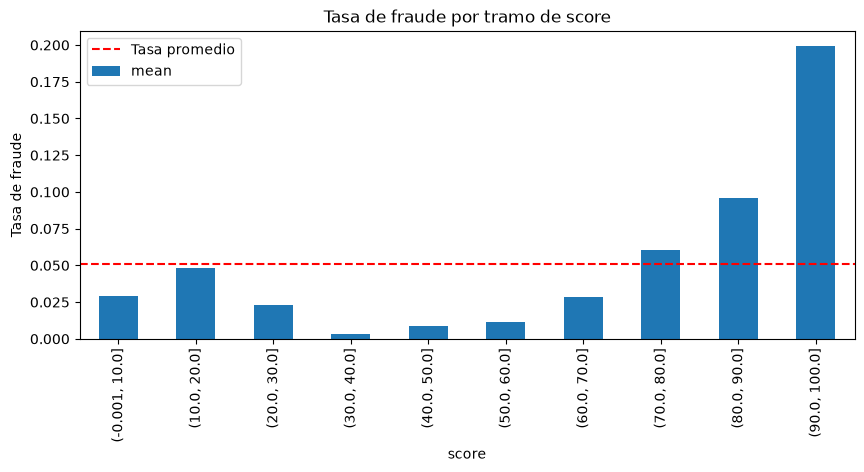

In [11]:
fraude_por_score["mean"].plot(kind="bar", figsize=(10, 4), title="Tasa de fraude por tramo de score")
plt.axhline(entrenamiento["fraude"].mean(), color="red", linestyle="--", label="Tasa promedio")
plt.ylabel("Tasa de fraude")
plt.legend()
plt.show()

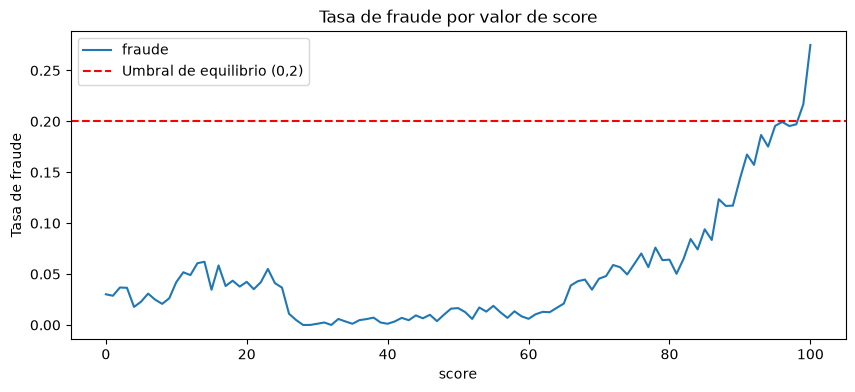

In [ ]:
#Análisis por cada puntaje del score (1 a 1) - comparado con el umbral teorico que maximiza la ganancia
fraude_por_valor = entrenamiento.groupby("score")["fraude"].mean()

fraude_por_valor.plot(figsize=(10, 4), title="Tasa de fraude por valor de score")
plt.axhline(0.2, color="red", linestyle="--", label="Umbral de equilibrio (0,2)")
plt.ylabel("Tasa de fraude")
plt.legend()
plt.show()

### Conclusiones de la sección 3

**Observaciones:**
- El score funciona en dirección directa: un valor alto indica más riesgo. La tasa de fraude
  va de 0,3% en el tramo 30-40 a 20% en el tramo 90-100.
- No es ordenado en los valores bajos: entre 0 y 25 la tasa se mantiene entre 3% y 6%,
  cae bruscamente cerca de 25 y queda casi en cero hasta 60. El score actual tiene un punto ciego:
  una regla que rechace scores altos nunca atrapa ese fraude.
- Por transacción, la tasa supera el umbral de equilibrio (0,2) solo en los valores más altos
  (alrededor de 98). Rechazar todo el tramo 90-100, cuya tasa es 0,1997, dejaría una ganancia casi nula.

**Decisiones para el modelo:**
- El corte del benchmark se elegirá maximizando la ganancia en validación, porque la ganancia
  depende del monto y no solo de la cantidad de fraudes.
- Si el score se usa como variable, los modelos de árboles capturan su forma irregular;
  una regresión logística necesitaría transformarlo en tramos.
- El fraude de los scores bajos es una oportunidad concreta para que el modelo nuevo
  supere al score actual.

## 4. Variables numéricas y fraude

In [ ]:
# Función para análizar las variables numericas vs el fraude
def tasa_por_tramos(datos, columna, q=10):
    #Tasa de fraude por decil de una variable numérica (nulos como aparte)
    tramos = pd.qcut(datos[columna], q=q, duplicates="drop")
    tabla = datos.groupby(tramos, observed=True)["fraude"].agg(["count", "mean"])
    tabla.index = tabla.index.astype(str)

    nulos = datos[datos[columna].isna()]
    if len(nulos) > 0:
        tabla.loc["nulo"] = [len(nulos), nulos["fraude"].mean()]
    return tabla

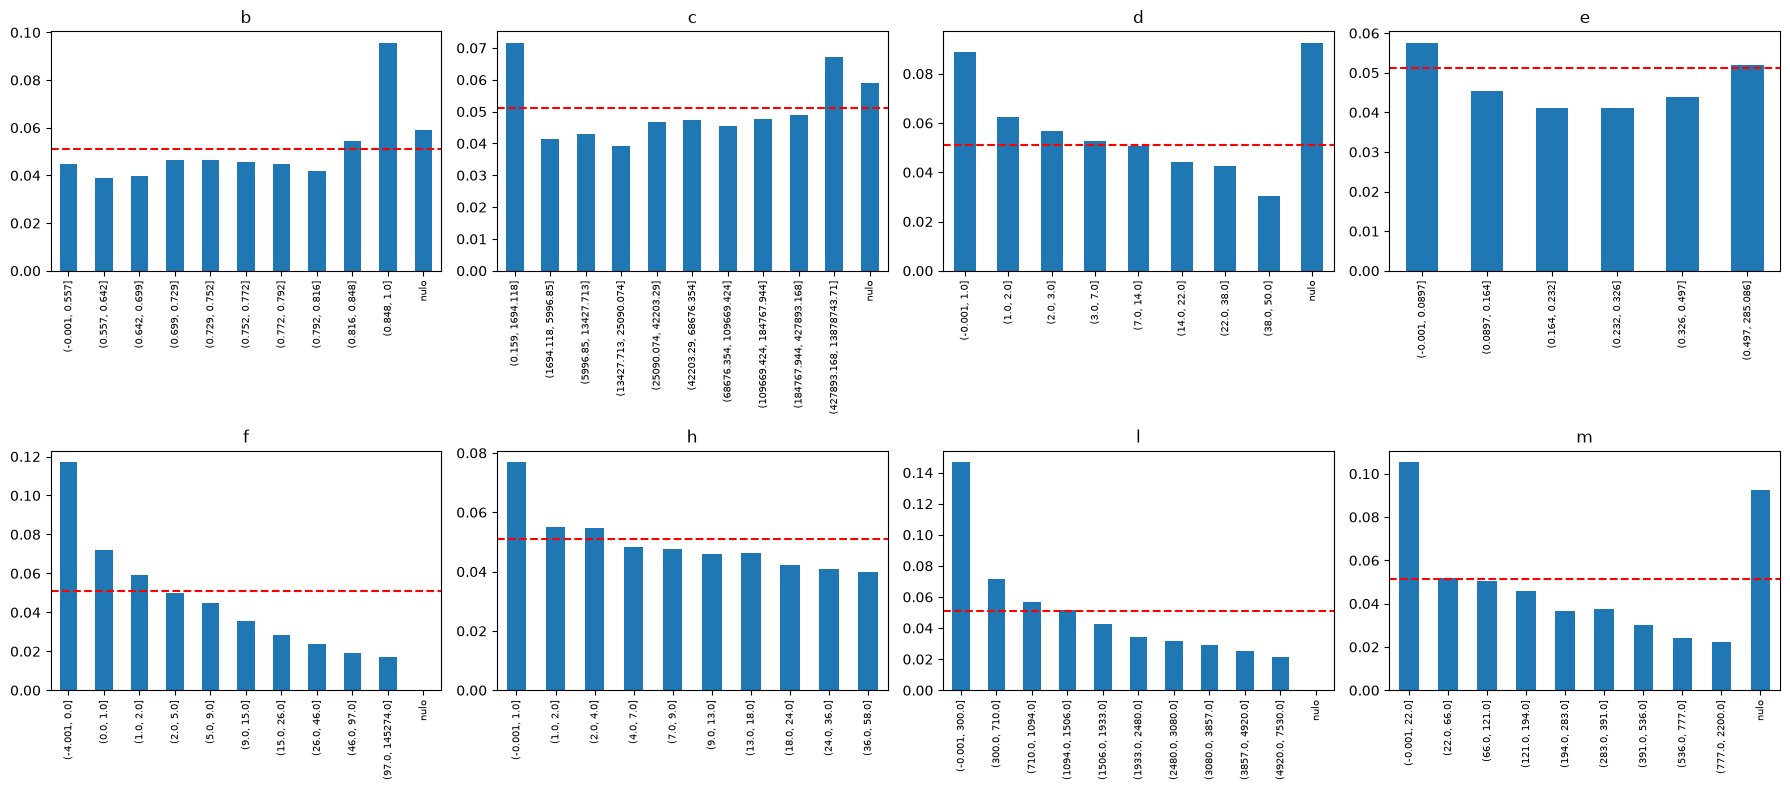

In [14]:
variables_numericas = ["b", "c", "d", "e", "f", "h", "l", "m"]
tasa_promedio = entrenamiento["fraude"].mean()

fig, ejes = plt.subplots(2, 4, figsize=(18, 8))
for columna, eje in zip(variables_numericas, ejes.flat):
    tasa_por_tramos(entrenamiento, columna)["mean"].plot(kind="bar", ax=eje, title=columna)
    eje.axhline(tasa_promedio, color="red", linestyle="--")
    eje.set_xlabel("")
    eje.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.show()

In [ ]:
# Analizando los nulos de las variables correpondietes
for columna in ["b", "d", "f"]:
    es_nulo = entrenamiento[columna].isna()
    print(
        f"{columna}: {es_nulo.sum()} nulos, "
        f"{entrenamiento.loc[es_nulo, 'fraude'].sum()} fraudes, "
        f"tasa {entrenamiento.loc[es_nulo, 'fraude'].mean() * 100:.1f}%"
    )

b: 12453 nulos, 736 fraudes, tasa 5.9%
d: 270 nulos, 25 fraudes, tasa 9.3%
f: 8 nulos, 0 fraudes, tasa 0.0%


In [ ]:
# Detalle de la variable b (muchos nulos)
semana = entrenamiento["fecha"].dt.to_period("W")
nulos_b_semana = entrenamiento.groupby(semana)["b"].apply(lambda serie: serie.isna().mean() * 100).round(1)
nulos_b_semana

fecha
2020-03-02/2020-03-08     0.8
2020-03-09/2020-03-15    47.9
2020-03-16/2020-03-22     1.1
2020-03-23/2020-03-29     1.1
2020-03-30/2020-04-05     1.0
Freq: W-SUN, Name: b, dtype: float64

In [ ]:
# Tasa de fraude en el incidente (ver si hay impacto)
semana_incidente = entrenamiento[semana == "2020-03-09/2020-03-15"]

(
    semana_incidente
    .groupby(semana_incidente["b"].isna())["fraude"]
    .agg(["count", "sum", "mean"])
    .rename(index={False: "b con dato", True: "b nulo"})
)

,count,sum,mean
b,,,
b con dato,12770,587,0.045967
b nulo,11753,597,0.050796


In [ ]:
# Detalle dia por dia de la semana del incidente
(
    semana_incidente
    .groupby(semana_incidente["fecha"].dt.date)["b"]
    .apply(lambda serie: serie.isna().mean() * 100)
    .round(1)
)

fecha
2020-03-09     62.2
2020-03-10     42.3
2020-03-11     40.4
2020-03-12    100.0
2020-03-13     62.0
2020-03-14      1.2
2020-03-15      0.9
Name: b, dtype: float64

### Conclusiones de la sección 4

**Observaciones:**
- `f`, `l`, `m`, `d` y `h` muestran una relación decreciente: a menor valor, más fraude.
  `f`, `l` y `m` tienen el contraste más fuerte entre sus tramos extremos.
- `b` tiene más fraude solo en sus valores más altos, y `c` tiene forma de U
  (más fraude en los extremos).
- `e` casi no muestra relación con el fraude.
- Los nulos de `b` y `c` vienen casi todos de un incidente de datos: del 9 al 13 de marzo,
  entre 40% y 100% de las transacciones no registraron estas variables. El resto del periodo
  tienen alrededor de 1% de nulos. Dentro de esa semana, la tasa de fraude es similar con y sin dato
  (5,1% y 4,6%), lo que indica una falla mayormente aleatoria.
- Los nulos de `d` y `m` (270 transacciones, 25 fraudes) tienen una tasa de 9,3%, pero la muestra
  es pequeña para concluir. Los de `f` y `l` (8 transacciones) no permiten sacar conclusiones.

**Decisiones para el modelo:**
- Se conservan los nulos como valores faltantes: LightGBM los maneja de forma nativa.
- No se crea una variable indicadora de nulos para `b` y `c`, porque solo representaría
  el incidente, que no existe en producción.
- No se eliminan las filas del incidente, para no perder alrededor del 13% del entrenamiento.
- Para la regresión logística, las variables con formas irregulares (`b`, `c`) se transformarán
  en tramos, y los nulos se imputarán.
- Este incidente es un ejemplo de por qué en producción conviene monitorear
  el porcentaje de nulos por variable.

## 5. Variables categóricas y fraude

### 5.1 Variables de pocos valores

In [ ]:
# Análisis de variables con pocos valores unicos (se incluyen a y n) 
#cantidad de trx por variable, cantidad de fraudes, tasa de fraude respectivamente y % de fraude
for columna in ["a", "n", "o", "p"]:
    tabla = entrenamiento.groupby(columna, dropna=False)["fraude"].agg(["count", "sum", "mean"])
    tabla["pct_fraudes"] = (tabla["sum"] / entrenamiento["fraude"].sum() * 100).round(1)
    print(f"--- {columna} ---")
    print(tabla, "\n")

--- a ---
   count   sum      mean  pct_fraudes
a                                    
1   2442   216  0.088452          4.7
2   9571   708  0.073973         15.4
3   1839   171  0.092985          3.7
4  76211  3512  0.046083         76.2 

--- n ---
   count   sum      mean  pct_fraudes
n                                    
0   8604  1450  0.168526         31.5
1  81459  3157  0.038756         68.5 

--- o ---
     count   sum      mean  pct_fraudes
o                                      
N    10150  2278  0.224433         49.4
Y    14643   961  0.065629         20.9
NaN  65270  1368  0.020959         29.7 

--- p ---
   count   sum      mean  pct_fraudes
p                                    
N  39791  3115  0.078284         67.6
Y  50272  1492  0.029679         32.4 



In [22]:
entrenamiento.groupby(semana)["o"].apply(lambda serie: serie.isna().mean() * 100).round(1)

fecha
2020-03-02/2020-03-08    71.5
2020-03-09/2020-03-15    72.7
2020-03-16/2020-03-22    72.6
2020-03-23/2020-03-29    72.5
2020-03-30/2020-04-05    72.0
Freq: W-SUN, Name: o, dtype: float64